# 📝 Character-Level Language Model (MLP)
This notebook implements a character-level Multi-Layer Perceptron (MLP) language model to generate names, similar to the Bengio et al. 2003 architecture.

## 1. Setup and Imports
We begin by importing the required packages: `torch` for modeling, `pandas` and `numpy` for data manipulation, and `matplotlib` for plotting progress.

In [234]:
import torch
import torch.nn as nn
import numpy as numpy
import pandas as pd
import matplotlib.pyplot as plt
import random
random.seed(42)
torch.manual_seed(42)
device="cuda" if torch.cuda.is_available() else "cpu"

## 2. Dataset Loading and Character Mapping
Next, we load the list of names from our text file, shuffle them for uniform distribution, and build our vocabulary index maps (bijective character-to-index mapping).

In [235]:
names=open("/content/names.txt","r").read().splitlines()
random.shuffle(names)

In [236]:
names[:30]

['yuheng',
 'diondre',
 'xavien',
 'jori',
 'juanluis',
 'erandi',
 'phia',
 'samatha',
 'phoenix',
 'emmelynn',
 'hollan',
 'hollis',
 'callalily',
 'adelayde',
 'josephyne',
 'weldon',
 'kayle',
 'ragnar',
 'colbie',
 'taveon',
 'aki',
 'peyten',
 'kevari',
 'joella',
 'mecca',
 'egan',
 'justyce',
 'taliyah',
 'hayley',
 'alleah']

In [237]:
chars=set("".join(names))
chars=list(sorted(chars))
chars

['a',
 'b',
 'c',
 'd',
 'e',
 'f',
 'g',
 'h',
 'i',
 'j',
 'k',
 'l',
 'm',
 'n',
 'o',
 'p',
 'q',
 'r',
 's',
 't',
 'u',
 'v',
 'w',
 'x',
 'y',
 'z']

In [238]:
char_to_index={}
index_to_char={}
char_to_index['.']=0
index_to_char[0]='.'
for ch in chars:
  char_to_index[ch]=len(char_to_index)
  index_to_char[char_to_index[ch]]=ch


In [239]:
char_to_index


{'.': 0,
 'a': 1,
 'b': 2,
 'c': 3,
 'd': 4,
 'e': 5,
 'f': 6,
 'g': 7,
 'h': 8,
 'i': 9,
 'j': 10,
 'k': 11,
 'l': 12,
 'm': 13,
 'n': 14,
 'o': 15,
 'p': 16,
 'q': 17,
 'r': 18,
 's': 19,
 't': 20,
 'u': 21,
 'v': 22,
 'w': 23,
 'x': 24,
 'y': 25,
 'z': 26}

In [240]:
index_to_char

{0: '.',
 1: 'a',
 2: 'b',
 3: 'c',
 4: 'd',
 5: 'e',
 6: 'f',
 7: 'g',
 8: 'h',
 9: 'i',
 10: 'j',
 11: 'k',
 12: 'l',
 13: 'm',
 14: 'n',
 15: 'o',
 16: 'p',
 17: 'q',
 18: 'r',
 19: 's',
 20: 't',
 21: 'u',
 22: 'v',
 23: 'w',
 24: 'x',
 25: 'y',
 26: 'z'}

## 3. Creating the Sliding Window Dataset
We prepare our training patterns by sliding a context window of size $N$ (configured here as `window_size = 5`) over each name to predict the subsequent character.

In [241]:
window_size=5
X,Y=[],[]
for name in names:
  name+="."
  context=[char_to_index["."]]*window_size
  for ch in name:
    idx=char_to_index[ch]
    X.append(context)
    Y.append(idx)
    context=context[1:]+[idx]


In [242]:
len(X)

228146

In [243]:
X=torch.tensor(X)
Y=torch.tensor(Y)

In [244]:
X[20],Y[20]

(tensor([24,  1, 22,  9,  5]), tensor(14))

## 4. Dataset Splitting & PyTorch DataLoaders
We split our generated dataset into **Training (90%)**, **Validation/Development (5%)**, and **Test (5%)** splits. We then wrap them inside a custom PyTorch `Dataset` and `DataLoader` for batching.

In [245]:
train_size=int(0.9*len(X))
dev_size=int(0.05*len(X))
test_size=int(0.05*len(X))
train_size,dev_size,test_size

(205331, 11407, 11407)

In [246]:
X_train,Y_train=X[:train_size],Y[:train_size]
X_dev,Y_dev=X[train_size:train_size+dev_size],Y[train_size:train_size+dev_size]
X_test,Y_test=X[train_size+dev_size:],Y[train_size+dev_size:]
len(X_train),len(Y_train),len(X_test),len(Y_test),len(X_dev),len(Y_dev)

(205331, 205331, 11408, 11408, 11407, 11407)

In [247]:
from torch.utils.data import Dataset,DataLoader
class MyData(Dataset):
  def __init__(self,X,Y):
    super().__init__()
    self.X=X
    self.Y=Y
  def __len__(self):
    return len(self.X)
  def __getitem__(self,idx):
    return self.X[idx],self.Y[idx]



In [248]:
train_data=MyData(X_train,Y_train)
dev_data=MyData(X_dev,Y_dev)
test_data=MyData(X_test,Y_test)
train_loader=DataLoader(train_data,shuffle=True,batch_size=256)
dev_loader=DataLoader(dev_data,shuffle=True,batch_size=256)
test_loader=DataLoader(test_data,shuffle=True,batch_size=256)

## 5. Model Initialization & Parameters
We initialize the multi-layer neural network parameters including character embeddings, hidden layers, biases, and Batch Normalization gains and biases.

In [249]:
hidden_units=300
emb_dim=100
C = torch.randn((27, emb_dim), device=device).requires_grad_(True)
W1=(torch.randn((emb_dim*window_size,hidden_units),device=device)*0.01).requires_grad_(True)
W2=(torch.randn((hidden_units,27),device=device)*0.01).requires_grad_(True)
b2=torch.zeros(27,device=device).requires_grad_(True)
bngain=torch.ones((1,hidden_units),device=device,requires_grad=True)
bnbias=torch.zeros((1,hidden_units),device=device,requires_grad=True)
bnmean_running=torch.zeros((1,hidden_units),device=device,requires_grad=False)
bnstd_running=torch.ones((1,hidden_units),device=device,requires_grad=False)
parameters=[W1,W2,b2,C,bngain,bnbias]


In [250]:
optim=torch.optim.Adam(parameters,lr=0.0005)

In [251]:
number_of_total_paramters=sum([parameter.nelement() for parameter in parameters ])
number_of_total_paramters

161427

## 6. Training Pipeline
Here we define our evaluation and training routines, featuring regularized optimization via Adam and dynamic Batch Normalization updates.

In [252]:
def Calaculate_Loss(C,W1,W2,b2,Loader):
    total_loss=0
    n=0
    for i,(X,Y) in enumerate(Loader):
       X=X.to(device)
       Y=Y.to(device)
       emb_x=C[X]
       h=emb_x.view(emb_x.shape[0],window_size*emb_dim)@W1
       h=bngain*((h-bnmean_running)/bnstd_running)+bnbias
       h=torch.tanh(h)
       logits=h@W2+b2
       Loss=F.cross_entropy(logits,Y)
       total_loss+=Loss.item()
       n+=1
    return total_loss/n



In [253]:
import torch.nn.functional as F
def train(C,W1,W2,b2,Train_Loader,Test_Loader,optim,n_epochs,lambda_):
  train_losses=[]
  test_losses=[]
  for epoch in range(n_epochs):
    total_train_loss=0
    n=0
    for i,(X,Y) in enumerate(Train_Loader):
       X=X.to(device)
       Y=Y.to(device)
       optim.zero_grad()
       emb_x=C[X]
       h=emb_x.view(emb_x.shape[0],window_size*emb_dim)@W1
       meani=h.mean(0,keepdim=True)
       stdi=h.std(0,keepdim=True)
       h=bngain*(h-meani)/stdi+bnbias
       h=torch.tanh(h)
       logits=h@W2+b2
       reg=lambda_*((W1**2).sum()+(W2**2).sum())
       ce=F.cross_entropy(logits,Y)
       Loss=ce+reg
       Loss.backward()
       optim.step()
       with torch.no_grad():
        bnmean_running.mul_(0.99).add_(0.01 * meani)
        bnstd_running.mul_(0.99).add_(0.01 * stdi)
       total_train_loss+=ce.item()
       n+=1
    with torch.no_grad():
      Test_Loss=Calaculate_Loss(C,W1,W2,b2,Test_Loader)
    train_losses.append(total_train_loss/n)
    test_losses.append(Test_Loss)
    print(f"epoch {epoch+1} Train Loss = {train_losses[-1]} Test Loss = {test_losses[-1]}")
  return train_losses,test_losses





In [254]:
train_losses,dev_losses=train(C,W1,W2,b2,train_loader,dev_loader,optim,30,0.0015)

epoch 1 Train Loss = 2.284710405772531 Test Loss = 2.189985672632853
epoch 2 Train Loss = 2.1564890376360597 Test Loss = 2.154929447174072
epoch 3 Train Loss = 2.1238969947451523 Test Loss = 2.128507497575548
epoch 4 Train Loss = 2.1013831857726406 Test Loss = 2.1323681990305583
epoch 5 Train Loss = 2.0843433192183043 Test Loss = 2.0996511273913914
epoch 6 Train Loss = 2.069081857670586 Test Loss = 2.0937052382363213
epoch 7 Train Loss = 2.0591374568891703 Test Loss = 2.0882816420661077
epoch 8 Train Loss = 2.0488991857614196 Test Loss = 2.0875315109888715
epoch 9 Train Loss = 2.04258502539187 Test Loss = 2.0751373370488486
epoch 10 Train Loss = 2.0355087410319936 Test Loss = 2.0656175322002834
epoch 11 Train Loss = 2.028767117082256 Test Loss = 2.0824454413519966
epoch 12 Train Loss = 2.02399995392316 Test Loss = 2.0586305379867555
epoch 13 Train Loss = 2.018792826093149 Test Loss = 2.055398856268989
epoch 14 Train Loss = 2.015221207257671 Test Loss = 2.0590747674306233
epoch 15 Train

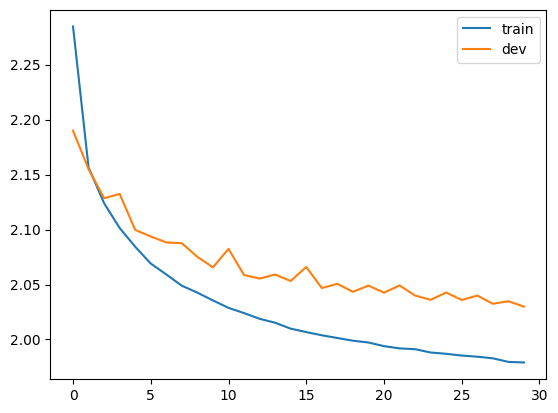

In [255]:
plt.plot(train_losses,label="train")
plt.plot(dev_losses,label="dev")
plt.legend()
plt.show()

### 📊 Key Observations from Training:
- **Smooth Convergence**: Both training and validation losses drop quickly within the first few epochs and converge steadily.
- **Regularization & Batch Normalization**: The model avoids heavy overfitting thanks to $L_2$ weight decay regularization and Batch Normalization layers.

In [256]:
with torch.no_grad():
      Test_Loss=Calaculate_Loss(C,W1,W2,b2,test_loader)
print(f"Test Loss : {Test_Loss}")

Test Loss : 2.0142608245213824


## 7. Sampling and Inference
With our model trained, we can now generate new names by starting with a sequence of padding characters (`.`) and iteratively sampling the next character from the model's output probability distribution.

In [257]:
def generate_words(n,block_size):
  for _ in range(n):
    out=""
    context="."*block_size
    while True:
      emb=C[torch.tensor([char_to_index[ch]for ch in context])]
      h=emb.view(1,-1)@W1
      h=(h-bnmean_running)/bnstd_running
      A1=torch.tanh(bngain*h+bnbias)
      logits=A1 @ W2+b2
      probs=torch.nn.functional.softmax(logits,dim=1)
      ix=torch.multinomial(probs,num_samples=1,replacement=True).item()
      if ix==0:
        print(out)
        break
      out+=index_to_char[ix]
      context=context[1:]+index_to_char[ix]








In [258]:
with torch.no_grad():
  generate_words(20,window_size)


tarik
viran
endre
rances
mairik
aio
fiora
shevin
jaylon
gemini
diylen
onyukuni
chers
insmia
viestani
kristan
kahcy
detrin
quilee
crued
